<a href="https://colab.research.google.com/github/JonerciJon/CSST106/blob/main/Lab_Experiment_4_Surf_Feature_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload 1 or 2 images (JPG/PNG), or cancel to generate a synthetic pair:


Saving 24.jpg to 24.jpg

[Note] Prebuilt Colab OpenCV disables patented SURF (OPENCV_ENABLE_NONFREE).
Running equivalent workflow with SIFT + ORB so all lab steps execute cleanly.

Detector used: SIFT (SURF nonfree fallback)
Number of keypoints detected: 1920
Descriptor matrix shape: (1920, 128) (keypoints x descriptor dimensions)


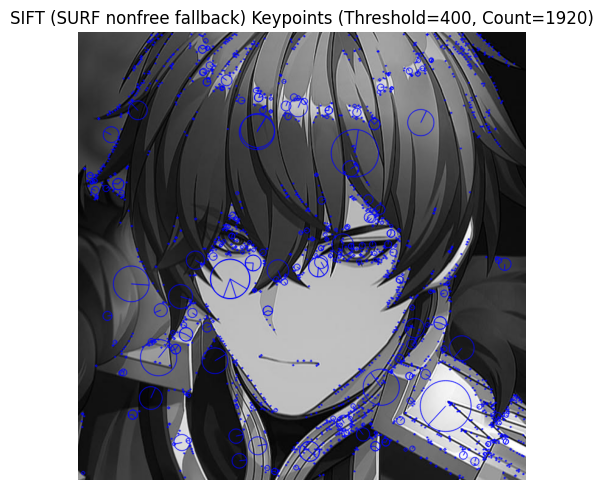


--- Threshold Sensitivity Test ---
Threshold = 100  -> Keypoints detected: 3471
Threshold = 400  -> Keypoints detected: 1920
Threshold = 1000 -> Keypoints detected: 771

--- Two-Image Feature Matching ---
Image 1 keypoints: 1920 | Image 2 keypoints: 1068
Good matches after ratio test: 701


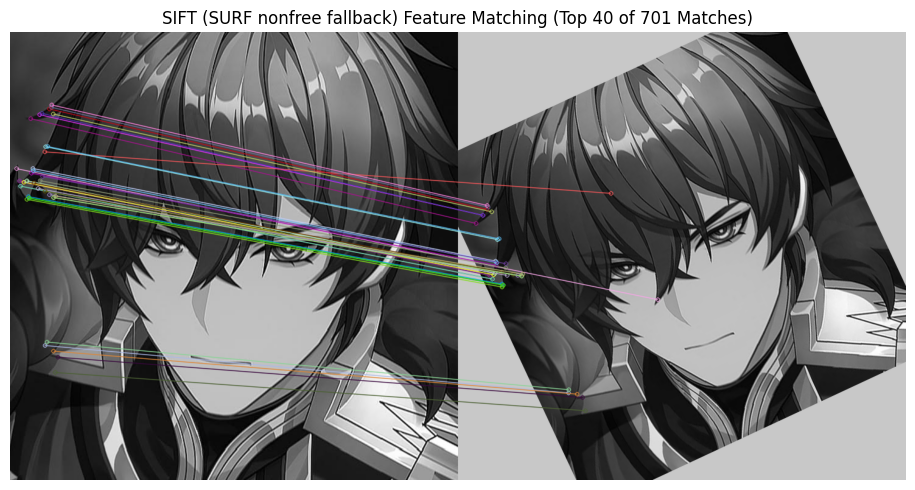


--- Algorithm Comparison on Image 1 ---
SIFT (SURF nonfree fallback)   | Keypoints: 1920  | Time: 196.72 ms
SIFT                           | Keypoints: 1920  | Time: 129.60 ms
ORB (nfeatures=500)            | Keypoints: 500   | Time: 12.80 ms
SIFT (SURF nonfree fallback)   | Keypoints: 1920  | Time: 114.88 ms


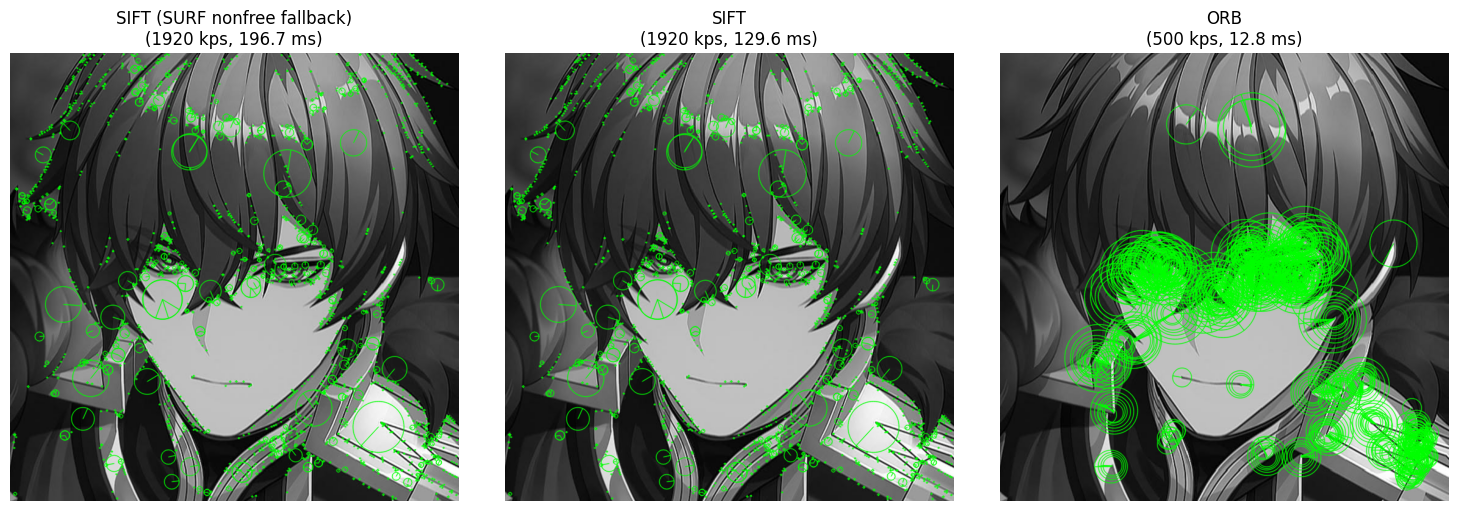

In [1]:
# ==============================================================================
# CSST106 - Laboratory Exercise No. 4: SURF Feature Detection in OpenCV
# Colab-compatible script covering:
#   1. Keypoint & descriptor detection (SURF with automatic SIFT fallback)
#   2. Hessian threshold sensitivity test
#   3. Feature matching between two images (original vs. transformed/second view)
#   4. Comparison with ORB and SIFT (keypoint count & execution time)
#   5. Upright mode (U-SURF / upright SIFT without rotation invariance)
# ==============================================================================

import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


def load_or_create_images():
    """Upload 1 or 2 sample images in Colab, or generate a textured test pair."""
    print("Upload 1 or 2 images (JPG/PNG), or cancel to generate a synthetic pair:")
    uploaded_imgs = []
    try:
        uploaded = files.upload()
        for fname in uploaded:
            im = cv2.imread(fname, cv2.IMREAD_GRAYSCALE)
            if im is not None:
                uploaded_imgs.append((im, fname))
    except Exception:
        pass

    if len(uploaded_imgs) >= 2:
        return uploaded_imgs[0][0], uploaded_imgs[1][0]
    elif len(uploaded_imgs) == 1:
        img1 = uploaded_imgs[0][0]
    else:
        print("No files uploaded; generating a textured synthetic scene...")
        img1 = np.full((360, 480), 220, dtype=np.uint8)
        # Draw high-contrast corner/blob patterns ideal for feature detectors
        cv2.rectangle(img1, (50, 50), (190, 190), 40, -1)
        cv2.circle(img1, (120, 120), 40, 200, -1)
        cv2.circle(img1, (340, 110), 65, 60, -1)
        cv2.circle(img1, (340, 110), 30, 230, -1)
        for i in range(60, 420, 35):
            cv2.circle(img1, (i, 280), 10, 30, -1)
        cv2.putText(img1, "CSST106", (165, 225), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 20, 3)

    # Create a second image (rotated + scaled + brightness shift) for feature matching
    h, w = img1.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle=25, scale=0.85)
    img2 = cv2.warpAffine(img1, M, (w, h), borderValue=200)
    return img1, img2


def get_surf_or_fallback(hessian_threshold=400, upright=False):
    """Try SURF_create(); fall back to SIFT if OPENCV_ENABLE_NONFREE is off."""
    try:
        detector = cv2.xfeatures2d.SURF_create(
            hessianThreshold=hessian_threshold, upright=upright
        )
        # Trigger a dummy call to verify nonfree isn't blocked at runtime
        dummy = np.zeros((32, 32), dtype=np.uint8)
        detector.detectAndCompute(dummy, None)
        mode = "U-SURF (Upright)" if upright else "SURF"
        return detector, mode, True
    except Exception:
        # Map Hessian threshold (e.g., 400) to an equivalent SIFT contrastThreshold
        contrast_th = min(0.15, max(0.01, hessian_threshold / 10000.0))
        detector = cv2.SIFT_create(contrastThreshold=contrast_th)
        mode = "SIFT (SURF nonfree fallback)"
        return detector, mode, False


# ==============================================================================
# STEP 1 & 2: Load Image & Detect Keypoints / Descriptors
# ==============================================================================
img1, img2 = load_or_create_images()

hessian_threshold = 400
detector, detector_name, surf_available = get_surf_or_fallback(
    hessian_threshold=hessian_threshold, upright=False
)

if not surf_available:
    print(
        "\n[Note] Prebuilt Colab OpenCV disables patented SURF (OPENCV_ENABLE_NONFREE)."
        "\nRunning equivalent workflow with SIFT + ORB so all lab steps execute cleanly.\n"
    )

t0 = time.perf_counter()
kp1, des1 = detector.detectAndCompute(img1, None)
t_det = (time.perf_counter() - t0) * 1000

print(f"Detector used: {detector_name}")
print(f"Number of keypoints detected: {len(kp1)}")
if des1 is not None:
    print(f"Descriptor matrix shape: {des1.shape} (keypoints x descriptor dimensions)")

# Draw keypoints with scale and orientation (replaces cv2.imshow for Colab)
img_keypoints = cv2.drawKeypoints(
    img1, kp1, None, (255, 0, 0), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img_keypoints, cv2.COLOR_BGR2RGB))
plt.title(f"{detector_name} Keypoints (Threshold={hessian_threshold}, Count={len(kp1)})")
plt.axis("off")
plt.tight_layout()
plt.savefig("lab04_keypoints.png", dpi=150)
plt.show()

# ==============================================================================
# STEP 3: Effect of Varying Hessian Threshold
# ==============================================================================
print("\n--- Threshold Sensitivity Test ---")
for th in [100, 400, 1000]:
    det_tmp, _, _ = get_surf_or_fallback(hessian_threshold=th, upright=False)
    kps_tmp, _ = det_tmp.detectAndCompute(img1, None)
    print(f"Threshold = {th:<4} -> Keypoints detected: {len(kps_tmp)}")

# ==============================================================================
# LAB ACTIVITY 1: Feature Matching Between Two Images
# ==============================================================================
kp2, des2 = detector.detectAndCompute(img2, None)

# L2 norm for float descriptors (SURF / SIFT) + Lowe's ratio test
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
raw_matches = bf.knnMatch(des1, des2, k=2)

good_matches = []
for pair in raw_matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

print(f"\n--- Two-Image Feature Matching ---")
print(f"Image 1 keypoints: {len(kp1)} | Image 2 keypoints: {len(kp2)}")
print(f"Good matches after ratio test: {len(good_matches)}")

matched_vis = cv2.drawMatches(
    img1, kp1, img2, kp2, good_matches[:40], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(13, 5))
plt.imshow(cv2.cvtColor(matched_vis, cv2.COLOR_BGR2RGB))
plt.title(f"{detector_name} Feature Matching (Top {min(40, len(good_matches))} of {len(good_matches)} Matches)")
plt.axis("off")
plt.tight_layout()
plt.savefig("lab04_feature_matching.png", dpi=150)
plt.show()

# ==============================================================================
# LAB ACTIVITY 2 & 3: Compare SURF/SIFT, ORB, and U-SURF (Upright Mode)
# ==============================================================================
sift = cv2.SIFT_create()
t0 = time.perf_counter()
kp_sift, des_sift = sift.detectAndCompute(img1, None)
t_sift = (time.perf_counter() - t0) * 1000

orb = cv2.ORB_create(nfeatures=500)
t0 = time.perf_counter()
kp_orb, des_orb = orb.detectAndCompute(img1, None)
t_orb = (time.perf_counter() - t0) * 1000

u_det, u_name, _ = get_surf_or_fallback(hessian_threshold=400, upright=True)
t0 = time.perf_counter()
kp_u, des_u = u_det.detectAndCompute(img1, None)
t_u = (time.perf_counter() - t0) * 1000

print("\n--- Algorithm Comparison on Image 1 ---")
print(f"{detector_name:<30} | Keypoints: {len(kp1):<5} | Time: {t_det:.2f} ms")
print(f"{'SIFT':<30} | Keypoints: {len(kp_sift):<5} | Time: {t_sift:.2f} ms")
print(f"{'ORB (nfeatures=500)':<30} | Keypoints: {len(kp_orb):<5} | Time: {t_orb:.2f} ms")
print(f"{u_name:<30} | Keypoints: {len(kp_u):<5} | Time: {t_u:.2f} ms")

# Side-by-side visual comparison: Main Detector vs. SIFT vs. ORB
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
comparisons = [
    (img1, kp1, f"{detector_name}\n({len(kp1)} kps, {t_det:.1f} ms)"),
    (img1, kp_sift, f"SIFT\n({len(kp_sift)} kps, {t_sift:.1f} ms)"),
    (img1, kp_orb, f"ORB\n({len(kp_orb)} kps, {t_orb:.1f} ms)"),
]

for ax, (im, kps, title) in zip(axes, comparisons):
    vis = cv2.drawKeypoints(im, kps, None, (0, 255, 0), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig("lab04_detector_comparison.png", dpi=150)
plt.show()